# Step 6 — Docking on the dopamine D2 receptor (AutoDock Vina)

Prepare and dock a ligand against the human D2 dopamine receptor (DRD2).

Activate the project's Vina environment, then run:
    conda install -c conda-forge vina meeko rdkit biopython pdbfixer openmm
    run all cells of this notebook

When prompted, enter the path to a ligand .sdf, .mol, or .smi file.

1. Global Setup and Project Information
Aim:To evaluate the binding pose and estimated affinity of several key reference compounds (including the native ligand risperidone and endogenous dopamine) against the prepared DRD2 receptor using AutoDock Vina.

Software and Packages Used:**
Python (Version 3.x)
`vina`: AutoDock Vina Python bindings for molecular docking.
`rdkit`, `meeko`: For 3D conformer generation and PDBQT ligand preparation.
`openmm`, `pdbfixer`, `biopython`: For repairing missing protein atoms and performing restrained energy minimization on the receptor.
`pandas`: For tabular data handling.

Global Settings & Parameters:
`BOX_PADDING_ANGSTROM = 8.0`: Expands the docking box beyond the native ligand to allow sufficient conformational sampling.
`EXHAUSTIVENESS = 8`: The Vina search exhaustiveness.
`NUM_MODES = 9`: The maximum number of binding modes to output per ligand.

Required Input Files:
`data/processed/crystal_structures/6CM4_Na.mmcif`: The processed DRD2 receptor structure.
`data/raw/crystal_structures/6cm4.mmcif`: The raw PDB structure.
`data/raw/comparison_smiles`: The target dataset containing SMILES for our baseline and comparison compounds.

In [1]:
from __future__ import annotations

import contextlib
import math
import shutil
import subprocess
import sys
import sysconfig
from pathlib import Path


## Settings

The receptor comes from the committed `data/processed/crystal_structures/6CM4_Na.mmcif` file. The local raw `6cm4.mmcif` is used only to locate co-crystallised risperidone (`8NU`) and define the docking box.

In [2]:
ROOT = Path(_dh[-1]).parent  # Repository root (this notebook lives in src/)

RUN_DIR = ROOT / "docking" / "runs"

RECEPTOR_NAME = "6CM4_Na"
RECEPTOR_CIF = ROOT / "data" / "processed" / "crystal_structures" / "6CM4_Na.mmcif"
NATIVE_LIGAND_REFERENCE_CIF = ROOT / "data" / "raw" / "crystal_structures" / "6cm4.mmcif"

SHARED_RECEPTOR_DIR = ROOT / "docking" / "prepared" / RECEPTOR_NAME

RISPERIDONE_COMPONENT_ID = "8NU"

# The processed PDBe file uses author residue numbering; these ranges are the
# two DRD2 segments, excluding the T4 lysozyme fusion and other ATOM records.
DRD2_AUTH_RESIDUE_RANGES = ((35, 222), (364, 442))

BOX_PADDING_ANGSTROM = 8.0

EXHAUSTIVENESS = 8

NUM_MODES = 9

## Check dependencies

Checks that Vina, Meeko, RDKit, Biopython, PDBFixer and OpenMM are installed and finds the Meeko preparation tools.

In [ ]:
def require_dependencies() -> dict[str, str]:
    """
    Check docking dependencies and locate the Meeko preparation tools.
    
    Returns:
        dict[str, str]: A dictionary mapping the tool names to their executable paths.
    """
    if sys.platform == "win32":
        raise RuntimeError(
            "This docking script uses AutoDock Vina's Python bindings, which are "
            "supported on Linux and macOS, not native Windows. Run it in Ubuntu "
            "under WSL instead. In your WSL terminal, activate the drd2-vina "
            "environment and run:\n"
            "  conda install -c conda-forge vina meeko rdkit biopython "
            "pdbfixer openmm\n"
            "Then run this script from the WSL terminal."
        )

    try:
        from Bio.PDB.MMCIF2Dict import MMCIF2Dict  # noqa: F401
        from openmm.app import PDBFile  # noqa: F401
        from pdbfixer import PDBFixer  # noqa: F401
        from rdkit import Chem  # noqa: F401
        from rdkit.Chem import AllChem  # noqa: F401
        from vina import Vina  # noqa: F401
    except ImportError as exc:
        raise RuntimeError(
            "A required package is missing. Activate the Vina environment and run:\n"
            "  conda install -c conda-forge vina meeko rdkit biopython pdbfixer openmm\n"
            "Then run this script again with `python vina_autodock.py`."
        ) from exc

    scripts_dir = Path(sysconfig.get_path("scripts"))
    tools = {}
    for tool in ("mk_prepare_receptor.py", "mk_prepare_ligand.py"):
        executable = shutil.which(tool)
        if executable is None:
            candidate = scripts_dir / (
                f"{tool}.exe" if sys.platform == "win32" else tool
            )
            if candidate.is_file():
                executable = str(candidate)
        if executable is not None:
            tools[tool] = executable
    missing_tools = set(("mk_prepare_receptor.py", "mk_prepare_ligand.py")) - tools.keys()
    if missing_tools:
        raise RuntimeError(
            "Meeko preparation tools were not found. Activate the Vina environment and run:\n"
            "  conda install -c conda-forge meeko\n"
            "Then run this script again from that environment."
        )
    return tools

## Read the local structures

In [ ]:
def cif_values(cif: dict, key: str) -> list[str]:
    """
    Return a mmCIF value as a list of strings.
    
    Args:
        cif (dict): Parsed mmCIF dictionary.
        key (str): The specific mmCIF record key to extract.
        
    Returns:
        list[str]: Extracted values as a list.
    """
    value = cif.get(key, [])
    if isinstance(value, str):
        return [value]
    return list(value)

## Extract the D2 receptor and define the docking box

The receptor atoms and the crystallographic Na+ coordinate come from the committed processed CIF. The raw local CIF is read only for co-crystallised risperidone coordinates, because the processed receptor file omits that ligand. The shared PDBQT contains the processed receptor and its Na+ ion.

In [ ]:
def make_receptor_and_box(
    receptor_cif_path: Path,
    ligand_reference_cif_path: Path,
    receptor_pdb: Path,
) -> tuple[list[float], list[float], tuple[float, float, float]]:
    """Extract DRD2 and Na+ from the processed CIF and box around native risperidone."""
    from Bio.PDB.MMCIF2Dict import MMCIF2Dict

    receptor_cif = MMCIF2Dict(str(receptor_cif_path))
    ligand_reference_cif = MMCIF2Dict(str(ligand_reference_cif_path))
    reference_components = set(cif_values(ligand_reference_cif, "_chem_comp.id"))
    if RISPERIDONE_COMPONENT_ID not in reference_components:
        raise ValueError(
            f"Expected risperidone component {RISPERIDONE_COMPONENT_ID} was not "
            f"found in local reference {ligand_reference_cif_path}."
        )

    fields = {
        "record": "_atom_site.group_PDB",
        "chain": "_atom_site.auth_asym_id",
        "sequence": "_atom_site.auth_seq_id",
        "component": "_atom_site.label_comp_id",
        "atom": "_atom_site.label_atom_id",
        "altloc": "_atom_site.label_alt_id",
        "insertion": "_atom_site.pdbx_PDB_ins_code",
        "x": "_atom_site.Cartn_x",
        "y": "_atom_site.Cartn_y",
        "z": "_atom_site.Cartn_z",
        "occupancy": "_atom_site.occupancy",
        "b_factor": "_atom_site.B_iso_or_equiv",
        "element": "_atom_site.type_symbol",
    }
    atom_columns = {
        name: cif_values(receptor_cif, key) for name, key in fields.items()
    }
    atom_count = len(atom_columns["record"])
    if not atom_count or any(len(values) != atom_count for values in atom_columns.values()):
        raise ValueError(f"Processed receptor {receptor_cif_path} has incomplete atom records.")

    ligand_records = {
        name: cif_values(ligand_reference_cif, key)
        for name, key in {
            "record": "_atom_site.group_PDB",
            "component": "_atom_site.label_comp_id",
            "element": "_atom_site.type_symbol",
            "x": "_atom_site.Cartn_x",
            "y": "_atom_site.Cartn_y",
            "z": "_atom_site.Cartn_z",
        }.items()
    }
    ligand_atom_count = len(ligand_records["record"])
    if not ligand_atom_count or any(
        len(values) != ligand_atom_count for values in ligand_records.values()
    ):
        raise ValueError(f"Local ligand reference {ligand_reference_cif_path} is incomplete.")
    native_ligand_points = [
        tuple(float(ligand_records[axis][index]) for axis in ("x", "y", "z"))
        for index in range(ligand_atom_count)
        if ligand_records["record"][index] == "HETATM"
        and ligand_records["component"][index] == RISPERIDONE_COMPONENT_ID
        and ligand_records["element"][index].strip().upper() not in {"H", "D"}
    ]
    if not native_ligand_points:
        raise ValueError(
            f"No co-crystallised risperidone coordinates found in {ligand_reference_cif_path}."
        )

    alternate_occupancy: dict[tuple[str, str, str], dict[str, float]] = {}
    for index in range(atom_count):
        if atom_columns["record"][index] != "ATOM":
            continue
        altloc = atom_columns["altloc"][index]
        if altloc in (".", "?", " "):
            continue
        residue_key = (
            atom_columns["chain"][index],
            atom_columns["sequence"][index],
            atom_columns["insertion"][index],
        )
        occupancies = alternate_occupancy.setdefault(residue_key, {})
        occupancies[altloc] = occupancies.get(altloc, 0.0) + float(
            atom_columns["occupancy"][index]
        )
    preferred_altloc = {
        residue_key: max(occupancies, key=occupancies.get)
        for residue_key, occupancies in alternate_occupancy.items()
    }

    receptor_lines = ["REMARK DRD2 receptor from local 6CM4_Na.mmcif\n"]
    sodium_points: list[tuple[float, float, float]] = []
    serial = 1
    for index in range(atom_count):
        record = atom_columns["record"][index]
        component = atom_columns["component"][index]
        element = atom_columns["element"][index].strip().upper()
        point = tuple(float(atom_columns[axis][index]) for axis in ("x", "y", "z"))

        if record == "HETATM" and component == "NA" and element == "NA":
            sodium_points.append(point)
            continue
        if record != "ATOM":
            continue

        try:
            sequence_number = int(atom_columns["sequence"][index])
        except ValueError:
            continue
        if not any(
            start <= sequence_number <= end
            for start, end in DRD2_AUTH_RESIDUE_RANGES
        ):
            continue

        altloc = atom_columns["altloc"][index]
        if altloc not in (".", "?", " "):
            residue_key = (
                atom_columns["chain"][index],
                atom_columns["sequence"][index],
                atom_columns["insertion"][index],
            )
            if altloc != preferred_altloc.get(residue_key):
                continue
        residue_id = sequence_number
        insertion = atom_columns["insertion"][index]
        if insertion in (".", "?", " "):
            insertion = " "
        chain = atom_columns["chain"][index]
        atom_name = atom_columns["atom"][index]
        atom_field = (
            f"{atom_name:<4s}"
            if len(atom_name) == 4 or atom_name[:1].isdigit()
            else f" {atom_name:<3s}"
        )
        x, y, z = point
        occupancy = float(atom_columns["occupancy"][index])
        b_factor = float(atom_columns["b_factor"][index])
        receptor_lines.append(
            f"ATOM  {serial:5d} {atom_field} {component:>3s} {chain}"
            f"{residue_id:4d}{insertion:1s}   {x:8.3f}{y:8.3f}{z:8.3f}"
            f"{occupancy:6.2f}{b_factor:6.2f}          {element:>2s}\n"
        )
        serial += 1

    if len(sodium_points) != 1:
        raise ValueError(
            f"Expected exactly one Na+ ion in {receptor_cif_path}; found {len(sodium_points)}."
        )
    if serial == 1:
        raise ValueError(f"No DRD2 protein atoms were extracted from {receptor_cif_path}.")

    receptor_lines.extend(("TER\n", "END\n"))
    receptor_pdb.parent.mkdir(parents=True, exist_ok=True)
    receptor_pdb.write_text("".join(receptor_lines), encoding="ascii")

    axes = list(zip(*native_ligand_points))
    minimum = [min(axis) for axis in axes]
    maximum = [max(axis) for axis in axes]
    center = [(low + high) / 2 for low, high in zip(minimum, maximum)]
    size = [
        high - low + BOX_PADDING_ANGSTROM
        for low, high in zip(minimum, maximum)
    ]
    if not all(math.isfinite(value) for value in center) or not all(
        math.isfinite(value) and value > 0 for value in size
    ):
        raise ValueError("Could not calculate a valid docking box from native risperidone.")
    return center, size, sodium_points[0]


def add_sodium_to_pdbqt(
    receptor_pdbqt: Path,
    sodium_point: tuple[float, float, float],
) -> None:
    """Include the crystallographic Na+ in the final Vina receptor PDBQT."""
    lines = receptor_pdbqt.read_text(encoding="ascii").splitlines()
    lines = [
        line for line in lines
        if not (
            line.startswith(("ATOM  ", "HETATM"))
            and line[12:16].strip() == "NA"
            and line[77:].strip() == "Na"
        )
    ]
    serials = [
        int(line[6:11])
        for line in lines
        if line.startswith(("ATOM  ", "HETATM")) and line[6:11].strip().isdigit()
    ]
    serial = max(serials, default=0) + 1
    if serial > 99999:
        raise ValueError("No PDBQT atom serial numbers remain for the sodium ion.")
    x, y, z = sodium_point
    sodium_record = (
        f"ATOM  {serial:5d} {' NA '} {'NA':>3s} A{9999:4d}    "
        f"{x:8.3f}{y:8.3f}{z:8.3f}{1.0:6.2f}{0.0:6.2f}"
        f"    {1.0:+.3f} Na"
    )
    insert_at = next(
        (index for index, line in enumerate(lines) if line.startswith("END")),
        len(lines),
    )
    lines.insert(insert_at, sodium_record)
    receptor_pdbqt.write_text("\n".join(lines) + "\n", encoding="ascii")

## Repair and prepare the receptor

PDBFixer and restrained OpenMM minimisation are applied to the protein atoms. The sodium is retained from the processed CIF and added to the final receptor PDBQT after protein preparation, since the protein force-field repair step does not parameterise it. Meeko prepares the protein; the receptor cache is in `docking/prepared/6CM4_Na/`.

In [6]:
def repair_missing_atoms(receptor_pdb: Path, repaired_pdb: Path) -> None:
    """Rebuild missing atoms and relax the structure with positional restraints."""
    from openmm.app import PDBFile
    from pdbfixer import PDBFixer

    fixer = PDBFixer(filename=str(receptor_pdb))
    fixer.findMissingResidues()
    fixer.missingResidues = {}
    fixer.findNonstandardResidues()
    fixer.replaceNonstandardResidues()
    fixer.findMissingAtoms()
    fixer.addMissingAtoms()

    repaired_pdb.parent.mkdir(parents=True, exist_ok=True)
    with repaired_pdb.open("w", encoding="ascii") as output_file:
        PDBFile.writeFile(
            fixer.topology,
            fixer.positions,
            output_file,
            keepIds=True,
        )
    minimize_repaired_receptor(receptor_pdb, repaired_pdb)
    corrected = correct_terminal_oxygen_geometry(repaired_pdb)
    if corrected:
        print(f"Corrected anomalous terminal oxygen geometry in {corrected} residue(s).")

In [7]:
def prepare_shared_receptor(tools: dict[str, str]) -> tuple[list[float], list[float]]:
    """Prepare or reuse the local DRD2 receptor and return its docking box."""
    receptor_pdb = SHARED_RECEPTOR_DIR / "drd2_clean.pdb"
    repaired_receptor_pdb = SHARED_RECEPTOR_DIR / "drd2_repaired.pdb"
    receptor_pdbqt = SHARED_RECEPTOR_DIR / "drd2.pdbqt"
    cached_receptor_cif = SHARED_RECEPTOR_DIR / RECEPTOR_CIF.name
    cached_ligand_reference_cif = SHARED_RECEPTOR_DIR / NATIVE_LIGAND_REFERENCE_CIF.name

    for source in (RECEPTOR_CIF, NATIVE_LIGAND_REFERENCE_CIF):
        if not source.is_file():
            raise FileNotFoundError(f"Required local structure file not found: {source}")
    SHARED_RECEPTOR_DIR.mkdir(parents=True, exist_ok=True)
    source_pairs = (
        (RECEPTOR_CIF, cached_receptor_cif),
        (NATIVE_LIGAND_REFERENCE_CIF, cached_ligand_reference_cif),
    )
    if any(
        not cached.is_file() or source.read_bytes() != cached.read_bytes()
        for source, cached in source_pairs
    ):
        repaired_receptor_pdb.unlink(missing_ok=True)
        receptor_pdbqt.unlink(missing_ok=True)
        for source, cached in source_pairs:
            shutil.copyfile(source, cached)

    center, size, sodium_point = make_receptor_and_box(
        RECEPTOR_CIF,
        NATIVE_LIGAND_REFERENCE_CIF,
        receptor_pdb,
    )
    if all(path.is_file() for path in (repaired_receptor_pdb, receptor_pdbqt)):
        add_sodium_to_pdbqt(receptor_pdbqt, sodium_point)
        print(f"Reusing shared prepared receptor: {receptor_pdbqt}")
        return center, size

    print("Preparing shared DRD2 receptor for ligand screening...")
    repair_missing_atoms(receptor_pdb, repaired_receptor_pdb)
    run_preparation(
        [
            tools["mk_prepare_receptor.py"],
            "--read_pdb", str(repaired_receptor_pdb),
            "--write_pdbqt", str(receptor_pdbqt),
            "--box_center", *(f"{value:.3f}" for value in center),
            "--box_size", *(f"{value:.3f}" for value in size),
            "--delete_bad_res_from_box_radius", "8",
        ],
        "shared DRD2 receptor",
    )
    add_sodium_to_pdbqt(receptor_pdbqt, sodium_point)
    return center, size

In [ ]:
def minimize_repaired_receptor(
    receptor_pdb: Path,
    repaired_pdb: Path,
) -> None:
    """Relax rebuilt atoms while strongly restraining experimental heavy atoms."""
    import openmm
    from openmm import unit
    from openmm.app import ForceField, Modeller, NoCutoff, PDBFile, Simulation

    original_atoms = set()
    for line in receptor_pdb.read_text(encoding="ascii").splitlines():
        if line.startswith("ATOM  "):
            original_atoms.add(
                (line[21], line[22:26].strip(), line[26], line[12:16].strip())
            )

    pdb = PDBFile(str(repaired_pdb))
    modeller = Modeller(pdb.topology, pdb.positions)
    forcefield = ForceField("amber14-all.xml")
    modeller.addHydrogens(forcefield, pH=7.0)
    system = forcefield.createSystem(
        modeller.topology,
        nonbondedMethod=NoCutoff,
        constraints=None,
    )
    restraints = openmm.CustomExternalForce(
        "0.5*k*((x-x0)^2+(y-y0)^2+(z-z0)^2)"
    )
    for parameter in ("k", "x0", "y0", "z0"):
        restraints.addPerParticleParameter(parameter)

    positions = modeller.positions
    for atom in modeller.topology.atoms():
        if atom.element is None or atom.element.symbol in {"H", "D"}:
            continue
        residue = atom.residue
        atom_key = (
            residue.chain.id,
            residue.id.strip(),
            residue.insertionCode,
            atom.name,
        )
        position = positions[atom.index].value_in_unit(unit.nanometer)
        restraint_strength = 10000.0 if atom_key in original_atoms else 100.0
        restraints.addParticle(
            atom.index,
            [restraint_strength, position.x, position.y, position.z],
        )
    system.addForce(restraints)

    simulation = Simulation(
        modeller.topology,
        system,
        openmm.VerletIntegrator(0.001 unit.picoseconds),
    )
    simulation.context.setPositions(positions)
    openmm.LocalEnergyMinimizer.minimize(
        simulation.context,
        tolerance=10.0 unit.kilojoules_per_mole / unit.nanometer,
        maxIterations=1000,
    )
    minimized_positions = simulation.context.getState(getPositions=True).getPositions()
    with repaired_pdb.open("w", encoding="ascii") as output_file:
        PDBFile.writeFile(
            modeller.topology,
            minimized_positions,
            output_file,
            keepIds=True,
        )

    lines = repaired_pdb.read_text(encoding="ascii").splitlines(keepends=True)
    repaired_pdb.write_text(
        "".join(
            line for line in lines
            if not line.startswith(("ATOM  ", "HETATM"))
            or line[76:78].strip().upper() not in {"H", "D"}
        ),
        encoding="ascii",
    )

In [ ]:
def correct_terminal_oxygen_geometry(repaired_pdb: Path) -> int:
    """Move mispositioned terminal oxygens away from false RDKit bond distances."""
    lines = repaired_pdb.read_text(encoding="ascii").splitlines(keepends=True)
    residues: dict[tuple[str, str], dict[str, int]] = {}
    for index, line in enumerate(lines):
        if not line.startswith(("ATOM  ", "HETATM")):
            continue
        residue_key = (line[21], line[22:27])
        residues.setdefault(residue_key, {})[line[12:16].strip()] = index

    corrected = 0
    for atoms in residues.values():
        if not all(name in atoms for name in ("CA", "C", "O", "OXT")):
            continue

        def coordinates(atom_name: str) -> tuple[float, float, float]:
            """Read an atom's Cartesian coordinates from its PDB record."""
            line = lines[atoms[atom_name]]
            return tuple(float(line[start:start + 8]) for start in (30, 38, 46))

        ca, carbonyl_c, oxygen, terminal_oxygen = (
            coordinates(name) for name in ("CA", "C", "O", "OXT")
        )
        if math.dist(ca, terminal_oxygen) >= 1.8:
            continue

        ca_vector = tuple(ca[i] - carbonyl_c[i] for i in range(3))
        oxygen_vector = tuple(oxygen[i] - carbonyl_c[i] for i in range(3))

        def unit(vector: tuple[float, float, float]) -> tuple[float, float, float]:
            """Return the normalized form of a three-dimensional vector."""
            magnitude = math.sqrt(sum(value value for value in vector))
            if magnitude < 1e-8:
                raise ValueError("Could not repair degenerate terminal oxygen geometry.")
            return tuple(value / magnitude for value in vector)

        ca_direction = unit(ca_vector)
        oxygen_direction = unit(oxygen_vector)
        opposite_bisector = tuple(
            -(ca_direction[i] + oxygen_direction[i]) for i in range(3)
        )
        terminal_direction = unit(opposite_bisector)
        repaired_position = tuple(
            carbonyl_c[i] + 1.25 terminal_direction[i] for i in range(3)
        )

        index = atoms["OXT"]
        lines[index] = (
            lines[index][:30]
            + "".join(f"{value:8.3f}" for value in repaired_position)
            + lines[index][54:]
        )
        corrected += 1

    if corrected:
        repaired_pdb.write_text("".join(lines), encoding="ascii")
    return corrected

## Prepare the ligand

Reads a ligand from `.sdf`, `.mol` or `.smi`, keeps the organic component, adds hydrogens and generates a 3D conformer.

In [10]:
def create_ligand_sdf(source_path: Path, sdf_path: Path) -> None:
    """Read a ligand, generate a 3D conformer if needed, and write an SDF."""
    from rdkit import Chem
    from rdkit.Chem import AllChem

    suffix = source_path.suffix.lower()
    molecule = None
    if suffix == ".sdf":
        supplier = Chem.SDMolSupplier(str(source_path), removeHs=False)
        molecule = next((candidate for candidate in supplier if candidate is not None), None)
    elif suffix == ".mol":
        molecule = Chem.MolFromMolFile(str(source_path), removeHs=False)
    elif suffix in (".smi", ".smiles", ".txt"):
        smiles_tokens = source_path.read_text(encoding="utf-8-sig").strip().split()
        if not smiles_tokens:
            raise ValueError(f"No SMILES string found in {source_path}.")
        molecule = Chem.MolFromSmiles(smiles_tokens[0])
        if molecule is None:
            raise ValueError(
                f"Could not parse SMILES token {smiles_tokens[0]!r} from "
                f"{source_path}. Check the file contents and remove any "
                "unsupported characters."
            )
    else:
        raise ValueError("Use a ligand file ending in .sdf, .mol, .smi, .smiles, or .txt.")

    if molecule is None:
        raise ValueError(f"Could not read a valid molecule from {source_path}.")

    fragments = Chem.GetMolFrags(molecule, asMols=True, sanitizeFrags=True)
    if len(fragments) > 1:
        organic_fragments = [
            fragment
            for fragment in fragments
            if any(atom.GetAtomicNum() == 6 for atom in fragment.GetAtoms())
        ]
        if len(organic_fragments) != 1:
            raise ValueError(
                f"Ligand input contains {len(fragments)} disconnected fragments "
                f"and {len(organic_fragments)} carbon-containing components. "
                "Provide a single ligand or a salt with exactly one "
                "carbon-containing component; refusing to guess which component "
                "to dock."
            )

        ignored_fragments = [
            Chem.MolToSmiles(fragment)
            for fragment in fragments
            if fragment is not organic_fragments[0]
        ]
        molecule = organic_fragments[0]
        print(
            "Ignoring disconnected non-carbon fragment(s) for docking: "
            f"{', '.join(ignored_fragments)}. "
            f"Using ligand component {Chem.MolToSmiles(molecule)}."
        )

    molecule = Chem.AddHs(molecule, addCoords=molecule.GetNumConformers() > 0)
    has_3d = (
        molecule.GetNumConformers() > 0
        and molecule.GetConformer().Is3D()
    )
    if not has_3d:
        molecule.RemoveAllConformers()
        if AllChem.EmbedMolecule(molecule, randomSeed=22) != 0:
            raise ValueError("Could not generate a 3D conformer for the ligand.")
        if AllChem.MMFFHasAllMoleculeParams(molecule):
            AllChem.MMFFOptimizeMolecule(molecule)

    sdf_path.parent.mkdir(parents=True, exist_ok=True)
    writer = Chem.SDWriter(str(sdf_path))
    writer.write(molecule)
    writer.close()

In [11]:
def run_preparation(command: list[str], label: str) -> None:
    """Run a preparation command and raise an error if it fails."""
    print(f"Preparing {label}...")
    subprocess.run(command, check=True)

## Docking with AutoDock Vina

In [12]:
def dock(receptor_pdbqt: Path, ligand_pdbqt: Path, output_path: Path,
         log_path: Path, center: list[float], size: list[float]) -> None:
    """Dock a prepared ligand and save poses, scores, and the Vina log."""
    from vina import Vina

    vina = Vina(sf_name="vina", cpu=0)
    vina.set_receptor(str(receptor_pdbqt))
    vina.set_ligand_from_file(str(ligand_pdbqt))
    vina.compute_vina_maps(center=center, box_size=size)
    with log_path.open("w", encoding="utf-8") as log_file:
        with contextlib.redirect_stdout(log_file):
            vina.dock(exhaustiveness=EXHAUSTIVENESS, n_poses=NUM_MODES)
            vina.write_poses(str(output_path), n_poses=NUM_MODES, overwrite=True)
            scores = vina.score()
    print(f"Best Vina score: {scores[0]:.2f} kcal/mol")

## The ligand to dock

The compound to dock is defined here as a SMILES string, so the notebook records exactly
which molecule was docked. The SMILES below is the top hit from the step 6 ML prediction
(`s_2230__14934458__16949512`, predicted pIC50 7.73, as recorded in `results/tables/scaffold_zinc22_predicted_pIC50.csv`).

The SMILES is written to a `.smi` file, because the docking code reads the ligand from a
file. Results are written to `docking/runs/<LIGAND_NAME>/`.

top_hit_s2230_14934458: Cc1nc2n(c(=O)c1CCN1CCN(c3cccc(Cl)c3Cl)CC1)CCCC2


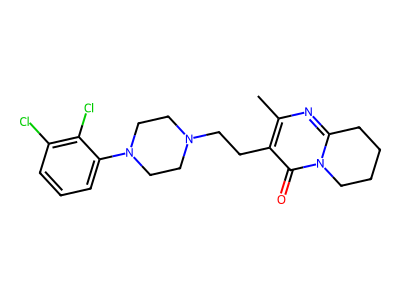

In [13]:
# Ligand to dock: top hit from the step 6 ML prediction
LIGAND_NAME = "top_hit_s2230_14934458"
LIGAND_SMILES = "CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl"

# Write the SMILES to a file, which is what the docking code reads
LIGAND_FILE = ROOT / "docking" / "examples" / "drd2" / f"{LIGAND_NAME}.smi"
LIGAND_FILE.parent.mkdir(parents=True, exist_ok=True)
LIGAND_FILE.write_text(LIGAND_SMILES + "\n", encoding="ascii")

# Show the molecule to confirm the SMILES is the intended compound
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display

molecule = Chem.MolFromSmiles(LIGAND_SMILES)
print(f"{LIGAND_NAME}: {Chem.MolToSmiles(molecule)}")
drawer = rdMolDraw2D.MolDraw2DSVG(400, 300)
drawer.DrawMolecule(molecule)
drawer.FinishDrawing()
display(SVG(drawer.GetDrawingText()))

In [14]:
def main(ligand_path) -> int:
    """Run ligand docking from input validation through pose generation."""
    try:
        tools = require_dependencies()
        raw_path = str(ligand_path).strip().strip('"')
        if not raw_path:
            raise ValueError("No ligand file was provided.")
        ligand_source = Path(raw_path.replace("\\", "/")).expanduser().resolve()
        if not ligand_source.is_file():
            raise FileNotFoundError(f"Ligand file not found: {ligand_source}")

        run_name = ligand_source.stem
        run_dir = RUN_DIR / run_name
        run_dir.mkdir(parents=True, exist_ok=True)

        center, size = prepare_shared_receptor(tools)
        for filename in (
            RECEPTOR_CIF.name,
            NATIVE_LIGAND_REFERENCE_CIF.name,
            "drd2_clean.pdb",
            "drd2_repaired.pdb",
            "drd2.pdbqt",
        ):
            shutil.copyfile(SHARED_RECEPTOR_DIR / filename, run_dir / filename)

        receptor_pdbqt = run_dir / "drd2.pdbqt"
        ligand_sdf = run_dir / "ligand_3d.sdf"
        ligand_pdbqt = run_dir / "ligand.pdbqt"
        output_path = run_dir / "docked_poses.pdbqt"
        log_path = run_dir / "vina.log"

        create_ligand_sdf(ligand_source, ligand_sdf)
        run_preparation(
            [
                tools["mk_prepare_ligand.py"],
                "-i", str(ligand_sdf),
                "-o", str(ligand_pdbqt),
            ],
            "ligand",
        )

        dock(receptor_pdbqt, ligand_pdbqt, output_path, log_path, center, size)
        print(f"Docking poses: {output_path}")
        print(f"Vina log: {log_path}")
        print(
            "Note: this is a docking score, not an experimental binding affinity. "
            "Review the receptor preparation and pose before interpreting it."
        )
        return 0
    except (RuntimeError, ValueError, FileNotFoundError, subprocess.CalledProcessError) as exc:
        print(f"Docking could not be completed: {exc}", file=sys.stderr)
        return 1

In [15]:
main(LIGAND_FILE)

Preparing shared DRD2 receptor for ligand screening...
Preparing shared DRD2 receptor...
Template padding will be used.
 gasteiger charges will be read from template file 
 

Files written:
/mnt/c/Users/manup/Documents/Leiden Universiteit/LUMC/Advanced Computational Methods in Drug Discovery/Mini-Research/drd2-antagonist-ml-docking/docking/prepared/6CM4_Na/drd2.pdbqt <-- static (i.e., rigid) receptor input file
Preparing ligand...
Input molecules processed: 1, skipped: 0
PDBQT files written: 1
PDBQT files not written due to error: 0
Input molecules with errors: 0
Computing Vina grid ... done.
Performing docking (random seed: -1478362703) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -10.33          0          0
   2       -9.896      1.51

0

# Batch docking: the top 100 predicted compounds from both sets

The cells above dock a single ligand. This batch docks **200 compounds total**: the top 100
by predicted pIC50 from the scaffold prediction set, followed by the top 100 from the random
ZINC22 prediction set. Both sets are docked; progress and successful docking counts are
reported separately as `scaffold` and `random` so the two groups are easy to distinguish.
The results are also saved separately for comparison with each set's ML ranking.

The receptor and docking box are prepared once and reused for every compound, so both sets are
docked under identical conditions. Each set has its own output folder; the shared receptor
files stay in `docking/prepared/6CM4_Na/`.

In [16]:
import pandas as pd

DATA = ROOT / "results" / "tables"

N_COMPOUNDS = 100
BATCHES = {
    "scaffold": {
        "predictions": pd.read_csv(DATA / "scaffold_zinc22_predicted_pIC50.csv"),
        "directory": RUN_DIR / "batch_top100_scaffold",
    },
    "random": {
        "predictions": pd.read_csv(DATA / "random_zinc22_predicted_pIC50.csv"),
        "directory": RUN_DIR / "batch_top100_random",
    },
}

for set_name, batch in BATCHES.items():
    batch["directory"].mkdir(parents=True, exist_ok=True)
    batch["top_compounds"] = batch["predictions"].nlargest(
        N_COMPOUNDS, "pred_pIC50"
    ).reset_index(drop=True)
    top_compounds = batch["top_compounds"]
    print(f"{set_name.title()} predictions: selected {len(top_compounds)} compounds")
    print(f"predicted pIC50 range: {top_compounds['pred_pIC50'].min():.2f} - "
          f"{top_compounds['pred_pIC50'].max():.2f}")
    display(top_compounds[["compound_id", "smiles", "pred_pIC50"]].head())

Scaffold predictions: selected 100 compounds
predicted pIC50 range: 7.10 - 7.81


,compound_id,smiles,pred_pIC50
0,s_2230__17793196__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.812313
1,s_2230__12304850__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.784896
2,s_2230__665554__16949512,COC1=CC=CC=C1N2CCN(CC2)CCC3=C(N=C4CCCCN4C3=O)C,7.778951
3,s_2230__9292524__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...,7.767475
4,s_2230__14934458__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...,7.729491


Random predictions: selected 100 compounds
predicted pIC50 range: 6.43 - 6.91


,compound_id,smiles,pred_pIC50
0,ZINCtQ00000Sk0Ja,Fc1cccc2[nH]c(=NCCCCN3CCC3)[nH]c(=NC[C@H]3CCCS...,6.911378
1,ZINCtQ00000Sk0Jb,Fc1cccc2[nH]c(=NCCCCN3CCC3)[nH]c(=N[C@@H]3CC[C...,6.888997
2,ZINCtl00001UEXnE,CN1CCC[C@H](CNc2c(NC[C@@H]3CCN(C)c4ccccc43)c(=...,6.708235
3,ZINCtT00000Sk0J9,Fc1cccc2[nH]c(=NCC=CCl)nc(N3CCN(Cc4ccc(Cl)s4)C...,6.662403
4,ZINCtt00000xdVjk,COC(=O)C12CCCC(NC(=O)[C@H](C)N3CCN(c4ccccc4F)C...,6.660748


In [ ]:
def dock_one_smiles(smiles, name, batch_dir, tools, receptor_pdbqt, center, size):
    """
    Extract DRD2 and Na+ from the processed CIF and establish the docking box around native risperidone.
    
    Args:
        receptor_cif_path (Path): Path to the processed receptor CIF.
        ligand_reference_cif_path (Path): Path to the native crystal structure.
        receptor_pdb (Path): Output path for the extracted receptor PDB.
        
    Returns:
        tuple: (box_center, box_size, sodium_ion_coordinates)
    """
    ligand_sdf = batch_dir / f"{name}_3d.sdf"
    ligand_pdbqt = batch_dir / f"{name}.pdbqt"
    poses_pdbqt = batch_dir / f"{name}_poses.pdbqt"

    # Same preparation as the single-ligand run: write the SMILES to a file first
    smi_path = batch_dir / f"{name}.smi"
    smi_path.write_text(smiles + "\n", encoding="ascii")
    create_ligand_sdf(smi_path, ligand_sdf)

    subprocess.run(
        [tools["mk_prepare_ligand.py"], "-i", str(ligand_sdf), "-o", str(ligand_pdbqt)],
        check=True, capture_output=True,
    )

    from vina import Vina

    vina = Vina(sf_name="vina", cpu=0, verbosity=0)
    vina.set_receptor(str(receptor_pdbqt))
    vina.set_ligand_from_file(str(ligand_pdbqt))
    vina.compute_vina_maps(center=center, box_size=size)
    vina.dock(exhaustiveness=EXHAUSTIVENESS, n_poses=NUM_MODES)
    vina.write_poses(str(poses_pdbqt), n_poses=NUM_MODES, overwrite=True)

    # The best score is stored in the first pose of the output file
    for line in poses_pdbqt.read_text().splitlines():
        if line.startswith("REMARK VINA RESULT:"):
            return float(line.split()[3])
    return None

In [18]:
%%time
tools = require_dependencies()
center, size = prepare_shared_receptor(tools)
receptor_pdbqt = SHARED_RECEPTOR_DIR / "drd2.pdbqt"

# Dock both prediction sets: 100 scaffold hits and 100 random hits.
for set_name, batch in BATCHES.items():
    top_compounds = batch["top_compounds"]
    scores = []
    print(f"\nDocking {set_name} set ({len(top_compounds)} compounds)")
    for i, row in top_compounds.iterrows():
        try:
            score = dock_one_smiles(
                row["smiles"], row["compound_id"], batch["directory"], tools,
                receptor_pdbqt, center, size,
            )
        except (ValueError, subprocess.CalledProcessError) as exc:
            print(f"  {row['compound_id']}: failed ({exc})")
            score = None
        scores.append(score)
        if (i + 1) % 10 == 0:
            print(f"  {set_name} docked {i + 1}/{len(top_compounds)}")

    top_compounds["vina_score"] = scores
    batch["results"] = top_compounds
    print(f"Docked {top_compounds['vina_score'].notna().sum()} of "
          f"{len(top_compounds)} {set_name} compounds")

Reusing shared prepared receptor: /mnt/c/Users/manup/Documents/Leiden Universiteit/LUMC/Advanced Computational Methods in Drug Discovery/Mini-Research/drd2-antagonist-ml-docking/docking/prepared/6CM4_Na/drd2.pdbqt

Docking scaffold set (100 compounds)
  scaffold docked 10/100
  scaffold docked 20/100
  scaffold docked 30/100
  scaffold docked 40/100
  scaffold docked 50/100
  scaffold docked 60/100
  scaffold docked 70/100
  scaffold docked 80/100
  scaffold docked 90/100
  scaffold docked 100/100
Docked 100 of 100 scaffold compounds

Docking random set (100 compounds)
  random docked 10/100
  random docked 20/100
  random docked 30/100
  random docked 40/100
  random docked 50/100
  random docked 60/100
  random docked 70/100
  random docked 80/100
  random docked 90/100
  random docked 100/100
Docked 100 of 100 random compounds
CPU times: user 6h 17min 45s, sys: 1min 12s, total: 6h 18min 58s
Wall time: 58min 12s


## Results: ML ranking vs docking ranking

A Vina score is **not*an affinity and must not be combined arithmetically with a predicted
pIC50 — the two methods estimate different things. Comparing the two rankings is still useful:
compounds that score well by both are the most sensible candidates to look at further.

2. Interpretation of Baseline Docking Results
Purpose: Export the Vina scores and interpret the binding affinities of the reference compounds.

In [19]:
for set_name, batch in BATCHES.items():
    results = batch["results"].dropna(subset=["vina_score"]).copy()
    results["ml_rank"] = results["pred_pIC50"].rank(ascending=False).astype(int)
    results["docking_rank"] = results["vina_score"].rank(ascending=True).astype(int)

    out_csv = DATA / f"top100_docking_results_{set_name}.csv"
    results.to_csv(out_csv, index=False)
    batch["successful_results"] = results
    print(f"Wrote {len(results)} {set_name} results to {out_csv}")
    print(f"\nBest 10 {set_name} compounds by Vina score:")
    display(results.nsmallest(10, "vina_score")[
        ["compound_id", "pred_pIC50", "ml_rank", "vina_score", "docking_rank"]
    ])

Wrote 100 scaffold results to /mnt/c/Users/manup/Documents/Leiden Universiteit/LUMC/Advanced Computational Methods in Drug Discovery/Mini-Research/drd2-antagonist-ml-docking/results/tables/top100_docking_results_scaffold.csv

Best 10 scaffold compounds by Vina score:


,compound_id,pred_pIC50,ml_rank,vina_score,docking_rank
99,s_2230__2206656__16949512,7.102095,100,-11.734,1
95,s_2230__27337748__16949512,7.115227,96,-11.703,2
75,s_2230__22865356__16949512,7.174367,76,-11.514,3
84,s_2230__26079434__16949512,7.148775,85,-11.267,4
12,s_2230__22406464__9780156,7.531251,13,-11.085,5
96,s_2230__665714__16949512,7.109246,97,-11.049,6
61,s_2230__9420632__16949512,7.239159,62,-11.045,7
92,s_2230__25583134__16949512,7.122186,93,-11.027,8
67,s_2230__26079586__9780156,7.206693,68,-11.024,9
64,s_2230__26079408__16949512,7.229560,65,-11.022,10


Wrote 100 random results to /mnt/c/Users/manup/Documents/Leiden Universiteit/LUMC/Advanced Computational Methods in Drug Discovery/Mini-Research/drd2-antagonist-ml-docking/results/tables/top100_docking_results_random.csv

Best 10 random compounds by Vina score:


,compound_id,pred_pIC50,ml_rank,vina_score,docking_rank
55,ZINCsK00000cdJff,6.474307,56,-11.242,1
11,ZINCtV00000Sk0J7,6.598531,12,-10.428,2
14,ZINCtU00000Sk0J1,6.581408,15,-10.384,3
15,ZINCtU00000Sk0J3,6.578911,16,-10.338,4
52,ZINCsw00000xzIrl,6.478693,52,-10.255,5
13,ZINCsw00000xzIqK,6.591807,14,-10.157,6
51,ZINCsw00000xzIrk,6.478693,52,-10.143,7
49,ZINCtU00000Sk0J6,6.481191,50,-10.125,8
22,ZINCrp00000ROl6q,6.550578,23,-10.115,9
21,ZINCtV00001dgjDk,6.557666,22,-10.062,10


3. Correlation between ML Predictions and Docking Scores
Purpose: To compare the ranking from our 2D QSAR model (pIC50) against the 3D structure-based AutoDock Vina scores.
Interpretation of Results: A weak or moderate Spearman correlation indicates that the two methods (2D fingerprint ML vs. 3D physics-based docking) evaluate ligand suitability differently. 

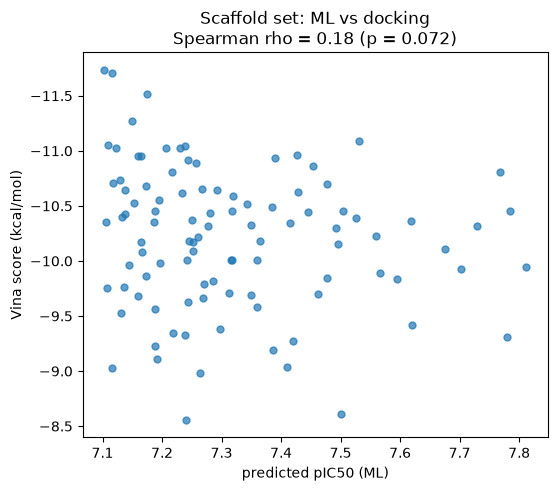

Scaffold set Spearman correlation: rho = 0.18, p = 0.072


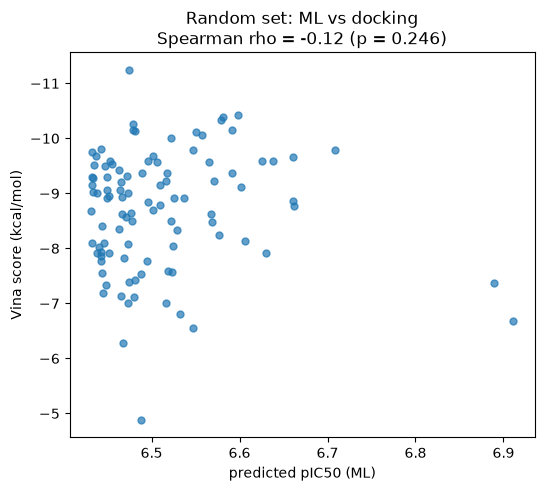

Random set Spearman correlation: rho = -0.12, p = 0.246


In [20]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

FIGURE_DIR = ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

for set_name, batch in BATCHES.items():
    results = batch["successful_results"]
    if len(results) < 2:
        print(f"Skipping {set_name} comparison plot: fewer than two compounds docked successfully")
        continue

    rho, pvalue = spearmanr(results["pred_pIC50"], results["vina_score"])
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(results["pred_pIC50"], results["vina_score"], s=25, alpha=0.7)
    ax.set_xlabel("predicted pIC50 (ML)")
    ax.set_ylabel("Vina score (kcal/mol)")
    ax.set_title(f"{set_name.title()} set: ML vs docking\n"
                 f"Spearman rho = {rho:.2f} (p = {pvalue:.3f})")
    ax.invert_yaxis()
    fig.savefig(FIGURE_DIR / f"ml_vs_docking_{set_name}.png", dpi=300,
                bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"{set_name.title()} set Spearman correlation: "
          f"rho = {rho:.2f}, p = {pvalue:.3f}")